In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score
from sklearn.decomposition import PCA
from sklearn.neighbors import NearestNeighbors
from sklearn.manifold import TSNE

csv_path = "/content/marketing_campaign.csv"
# This file is tab-separated, even though its extension is .csv.
raw = pd.read_csv(csv_path, sep="\t")

print("Dataset shape:", raw.shape)
display(raw.head())

Dataset shape: (2240, 29)


,ID,Year_Birth,Education,Marital_Status,Income,Kidhome,Teenhome,Dt_Customer,Recency,MntWines,...,NumWebVisitsMonth,AcceptedCmp3,AcceptedCmp4,AcceptedCmp5,AcceptedCmp1,AcceptedCmp2,Complain,Z_CostContact,Z_Revenue,Response
0,5524,1957,Graduation,Single,58138.0,0,0,04-09-2012,58,635,...,7,0,0,0,0,0,0,3,11,1
1,2174,1954,Graduation,Single,46344.0,1,1,08-03-2014,38,11,...,5,0,0,0,0,0,0,3,11,0
2,4141,1965,Graduation,Together,71613.0,0,0,21-08-2013,26,426,...,4,0,0,0,0,0,0,3,11,0
3,6182,1984,Graduation,Together,26646.0,1,0,10-02-2014,26,11,...,6,0,0,0,0,0,0,3,11,0
4,5324,1981,PhD,Married,58293.0,1,0,19-01-2014,94,173,...,5,0,0,0,0,0,0,3,11,0


In [2]:
raw.info()

print("\nMissing values in the first 15 columns:")
display(raw.isna().sum().sort_values(ascending=False).head(15))

print("\nNumeric summary:")
display(raw.describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2240 entries, 0 to 2239
Data columns (total 29 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   ID                   2240 non-null   int64  
 1   Year_Birth           2240 non-null   int64  
 2   Education            2240 non-null   object 
 3   Marital_Status       2240 non-null   object 
 4   Income               2216 non-null   float64
 5   Kidhome              2240 non-null   int64  
 6   Teenhome             2240 non-null   int64  
 7   Dt_Customer          2240 non-null   object 
 8   Recency              2240 non-null   int64  
 9   MntWines             2240 non-null   int64  
 10  MntFruits            2240 non-null   int64  
 11  MntMeatProducts      2240 non-null   int64  
 12  MntFishProducts      2240 non-null   int64  
 13  MntSweetProducts     2240 non-null   int64  
 14  MntGoldProds         2240 non-null   int64  
 15  NumDealsPurchases    2240 non-null   i

,0
Income,24
ID,0
Year_Birth,0
Education,0
Marital_Status,0
Kidhome,0
Teenhome,0
Dt_Customer,0
Recency,0
MntWines,0



Numeric summary:


,count,mean,std,min,25%,50%,75%,max
ID,2240.0,5592.159821,3246.662198,0.0,2828.25,5458.5,8427.75,11191.0
Year_Birth,2240.0,1968.805804,11.984069,1893.0,1959.00,1970.0,1977.00,1996.0
Income,2216.0,52247.251354,25173.076661,1730.0,35303.00,51381.5,68522.00,666666.0
Kidhome,2240.0,0.444196,0.538398,0.0,0.00,0.0,1.00,2.0
Teenhome,2240.0,0.506250,0.544538,0.0,0.00,0.0,1.00,2.0
Recency,2240.0,49.109375,28.962453,0.0,24.00,49.0,74.00,99.0
MntWines,2240.0,303.935714,336.597393,0.0,23.75,173.5,504.25,1493.0
MntFruits,2240.0,26.302232,39.773434,0.0,1.00,8.0,33.00,199.0
MntMeatProducts,2240.0,166.950000,225.715373,0.0,16.00,67.0,232.00,1725.0
MntFishProducts,2240.0,37.525446,54.628979,0.0,3.00,12.0,50.00,259.0


In [4]:
purchase_cols = [
    "NumWebPurchases",
    "NumCatalogPurchases",
    "NumStorePurchases",
]

monetary_cols = [col for col in raw.columns if col.startswith("Mnt")]

rfm = pd.DataFrame({
    "CustomerID": raw["ID"],
    "Recency": raw["Recency"],
    "Frequency": raw[purchase_cols].sum(axis=1),
    "Monetary": raw[monetary_cols].sum(axis=1),
}).dropna()

display(rfm.head())

,CustomerID,Recency,Frequency,Monetary
0,5524,58,22,1617
1,2174,38,4,27
2,4141,26,20,776
3,6182,26,6,53
4,5324,94,14,422


In [5]:
X = rfm[["Recency", "Frequency", "Monetary"]].copy()

X[["Frequency", "Monetary"]] = np.log1p(
    X[["Frequency", "Monetary"]]
)

X_scaled = StandardScaler().fit_transform(X)

In [6]:
rfm["KMeans"] = KMeans(
    n_clusters=4,
    n_init=10,
    random_state=42,
).fit_predict(X_scaled)

distances, _ = NearestNeighbors(n_neighbors=5) \
    .fit(X_scaled) \
    .kneighbors(X_scaled)

eps = np.quantile(distances[:, -1], 0.85)

rfm["DBSCAN"] = DBSCAN(
    eps=eps,
    min_samples=5,
).fit_predict(X_scaled)

print("DBSCAN eps:", round(eps, 3))
print("K-Means silhouette score:",
      round(silhouette_score(X_scaled, rfm["KMeans"]), 3))
display(rfm[["KMeans", "DBSCAN"]].value_counts())

DBSCAN eps: 0.195
K-Means silhouette score: 0.422


KMeans  DBSCAN
0        0        655
3        0        583
2        4         95
         1         93
         0         89
1        2         89
2        2         85
1        0         84
         1         81
         3         72
         5         53
2       -1         38
1       -1         38
0       -1         36
1        4         33
2        10        30
3       -1         28
1        9         15
2        8          8
         6          8
1        11         6
2        3          5
3        7          5
1        12         5
         13         4
         6          2
Name: count, dtype: int64

In [7]:
profiles = rfm.groupby("KMeans")[
    ["Recency", "Frequency", "Monetary"]
].median()

overall = rfm[["Recency", "Frequency", "Monetary"]].median()

profiles["Persona"] = np.select(
    [
        (profiles.Recency <= overall.Recency)
        & (profiles.Frequency >= overall.Frequency)
        & (profiles.Monetary >= overall.Monetary),

        (profiles.Recency > overall.Recency)
        & (profiles.Monetary >= overall.Monetary),

        (profiles.Recency <= overall.Recency)
        & (profiles.Frequency >= overall.Frequency),

        (profiles.Recency > overall.Recency)
        & (profiles.Frequency < overall.Frequency),
    ],
    [
        "Champions / VIP",
        "High-value at risk",
        "Frequent buyers",
        "Dormant customers",
    ],
    default="Occasional buyers",
)

profiles["Marketing Action"] = profiles["Persona"].map({
    "Champions / VIP": "Offer loyalty rewards or referral perks",
    "High-value at risk": "Send a personalized win-back offer",
    "Frequent buyers": "Offer bundles or replenishment reminders",
    "Dormant customers": "Try a reactivation message",
    "Occasional buyers": "Send product recommendations",
})

display(profiles)

,Recency,Frequency,Monetary,Persona,Marketing Action
KMeans,,,,,
0,72.0,17.0,960.0,High-value at risk,Send a personalized win-back offer
1,25.0,5.0,55.5,Occasional buyers,Send product recommendations
2,77.0,5.0,61.0,Dormant customers,Try a reactivation message
3,23.0,18.0,914.5,Champions / VIP,Offer loyalty rewards or referral perks


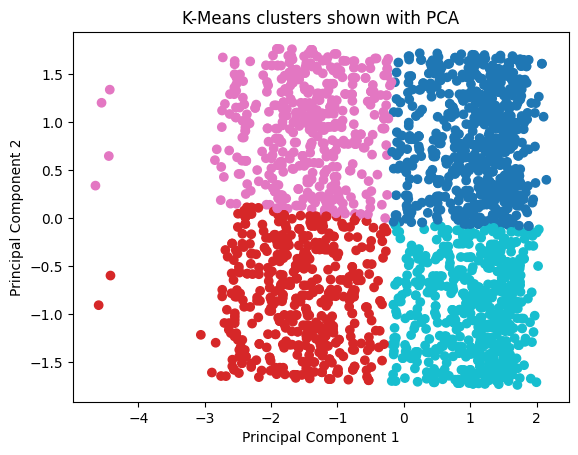

In [8]:
pca_points = PCA(n_components=2).fit_transform(X_scaled)

plt.scatter(
    pca_points[:, 0],
    pca_points[:, 1],
    c=rfm["KMeans"],
    cmap="tab10",
)
plt.title("K-Means clusters shown with PCA")
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.show()

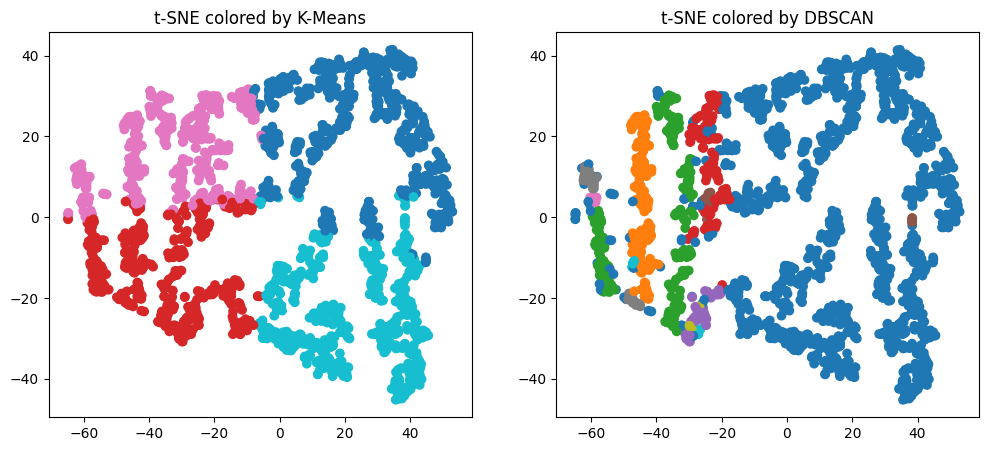

In [9]:
tsne_points = TSNE(
    n_components=2,
    perplexity=30,
    init="pca",
    learning_rate="auto",
    random_state=42,
).fit_transform(X_scaled)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

axes[0].scatter(
    tsne_points[:, 0], tsne_points[:, 1],
    c=rfm["KMeans"], cmap="tab10",
)
axes[0].set_title("t-SNE colored by K-Means")

axes[1].scatter(
    tsne_points[:, 0], tsne_points[:, 1],
    c=rfm["DBSCAN"], cmap="tab10",
)
axes[1].set_title("t-SNE colored by DBSCAN")

plt.show()

In [10]:
from google.colab import files
files.download(csv_path)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>